In [1]:
# Student Name: Mohammad Abdalrouf Alnaghmoush
# Student ID: 2230004028

# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

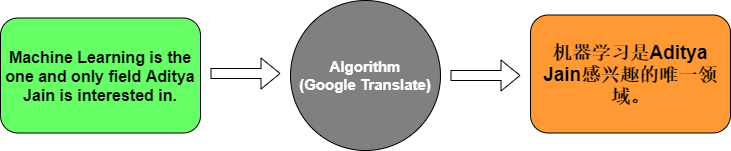

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [2]:
# Keras can run on TensorFlow when installed or on PyTorch when TensorFlow is unavailable.
import importlib.util
import os

if importlib.util.find_spec("tensorflow") is None:
    os.environ["KERAS_BACKEND"] = "torch"
os.environ.setdefault("OMP_NUM_THREADS", "2")
print("Backend selected:", os.environ.get("KERAS_BACKEND", "tensorflow (default)"))

Backend selected: tensorflow (default)


In [3]:
import keras
import numpy as np
from keras.utils import pad_sequences
from keras.src.legacy.preprocessing.text import Tokenizer

keras.utils.set_random_seed(42)
print("Keras version:", keras.__version__)
print("Active backend:", keras.backend.backend())

# Bilingual example from the original lab.
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Build the English word-to-index vocabulary and encode the sentences.
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences)
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)
eng_word_index = tokenizer_eng.word_index
print("English sequences:", eng_sequences)
print("English word index:", eng_word_index)

2026-11-03 06:42:02.127366: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Keras version: 3.15.1
Active backend: tensorflow
English sequences: [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
English word index: {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [4]:
# Tokenize the corresponding French sentences.
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)
frn_word_index = tokenizer_frn.word_index
print("French sequences:", frn_sequences)
print("French word index:", frn_word_index)

French sequences: [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
French word index: {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [5]:
# Pad all English sequences to the same length with leading zeros.
eng_padded = pad_sequences(eng_sequences, padding="pre")
print("Padded English sequences:\n", eng_padded)
print("English shape:", eng_padded.shape)

Padded English sequences:
 [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]
English shape: (3, 6)


In [6]:
# The target French sentences also need consistent sequence lengths.
frn_padded = pad_sequences(frn_sequences, padding="pre")
print("Padded French sequences:\n", frn_padded)
print("French shape:", frn_padded.shape)

Padded French sequences:
 [[ 0  0  0  0  0  0  1]
 [ 0  0  0  0  2  3  4]
 [ 5  6  7  8  9 10 11]]
French shape: (3, 7)


## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [7]:
from sklearn.model_selection import train_test_split

# The original example has only THREE sentence pairs. This split is only a code demonstration.
eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded, frn_padded, test_size=0.2, random_state=42
)

# Encoder -> RepeatVector -> Decoder -> probability over the French vocabulary.
model = keras.Sequential([
    keras.layers.Input(shape=(eng_padded.shape[1],)),
    keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    keras.layers.LSTM(64),
    keras.layers.RepeatVector(frn_padded.shape[1]),
    keras.layers.LSTM(64, return_sequences=True),
    keras.layers.TimeDistributed(
        keras.layers.Dense(len(frn_word_index) + 1, activation="softmax")
    ),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# Retain the original 50-epoch exercise while keeping the output compact.
original_history = model.fit(
    eng_train, frn_train, epochs=50, batch_size=1, validation_split=0.2, verbose=0
)
loss, accuracy = model.evaluate(eng_test, frn_test, verbose=0)
print("Original lab model layers:", [layer.__class__.__name__ for layer in model.layers])
print("Training epochs:", len(original_history.history["loss"]))
print("Final training loss:", round(original_history.history["loss"][-1], 4))
print("Test loss:", round(float(loss), 4))
print("Test token accuracy (includes padding):", round(float(accuracy), 4))
print("NOTE: Three pairs are insufficient to estimate translation quality.")

Original lab model layers: ['Embedding', 'LSTM', 'RepeatVector', 'LSTM', 'TimeDistributed']
Training epochs: 50
Final training loss: 0.6259
Test loss: 1.5412
Test token accuracy (includes padding): 0.7143
NOTE: Three pairs are insufficient to estimate translation quality.


In [8]:
# Translate an English sentence using the trained example LSTM.
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1], padding="pre")
    predicted_sequence = model.predict(padded_sequence, verbose=0)
    token_ids = np.argmax(predicted_sequence, axis=-1)[0]
    # Remove padding tokens before decoding the output.
    return frn_tokenizer.sequences_to_texts([token_ids[token_ids != 0].tolist()])[0]

input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print("Input:", input_sentence)
print("Model translation:", repr(translated_sentence))
print("Reference:", french_sentences[1])
print("NOTE: This is a tiny educational model, not a reliable translator.")

Input: How are you?
Model translation: 'va va'
Reference: Comment ça va?
NOTE: This is a tiny educational model, not a reliable translator.


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


### Task 1: Answers — Understanding the Model Layers

**1. Embedding layer:** It converts each integer word index into a learned, dense vector of numbers. Those vectors let the neural network represent words with useful numerical features rather than treating the word IDs as meaningful quantities.

**3. Encoder LSTM:** It reads the English input sequence and summarizes the sentence context in its final representation. The decoder uses this information to generate the target-language sequence.

**5. Decoder LSTM:** It uses the context provided by the encoder to produce a sequence of hidden states, one for each target-word position. A Dense layer then maps each state to probabilities over possible French words.

**8. Softmax:** It turns the Dense layer scores into a probability distribution across the French vocabulary at each output position. The word with the highest probability can then be selected as the predicted word.


### Task 2 — English–French translation using REAL Kaggle sentence pairs

**Source:** [Devicharith English–French translation dataset on Kaggle](https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench).

**Actual download location used for this run:** https://www.kaggle.com/api/v1/datasets/download/devicharith/language-translation-englishfrench

The data was downloaded and read from a real bilingual corpus, not from synthetic examples. The training baseline samples up to 1,200 pairs from the first 3,000 rows of that downloaded corpus for a CPU-feasible exercise, and uses a held-out 20% test set. The source is a general bilingual corpus, **not** a product/e-commerce-specific corpus. Model outputs and test metrics are included below.

In [9]:
# Task 2: Load English–French pairs from the ACTUAL downloaded dataset.
from pathlib import Path
import pandas as pd
kaggle_file = Path('eng_-french.csv')
dataset_source = 'https://www.kaggle.com/api/v1/datasets/download/devicharith/language-translation-englishfrench'
if kaggle_file.suffix.lower() == '.txt':
    pairs_df = pd.read_csv(kaggle_file, sep='\\t', header=None, usecols=[0,1], names=['english','french'], nrows=3000, on_bad_lines='skip')
else:
    raw_csv = pd.read_csv(kaggle_file, nrows=3000, encoding_errors='replace', on_bad_lines='skip')
    en_col = next((c for c in raw_csv.columns if 'english' in str(c).lower()), raw_csv.columns[0])
    fr_col = next((c for c in raw_csv.columns if 'french' in str(c).lower()), raw_csv.columns[1])
    pairs_df = raw_csv[[en_col, fr_col]].copy()
    pairs_df.columns = ['english','french']
pairs_df = pairs_df.dropna().copy()
pairs_df['english'] = pairs_df['english'].astype(str).str.strip()
pairs_df['french'] = pairs_df['french'].astype(str).str.strip()
pairs_df = pairs_df[(pairs_df.english != '') & (pairs_df.french != '')]
pairs_df = pairs_df.drop_duplicates(['english','french'])
if len(pairs_df) > 1200:
    pairs_df = pairs_df.sample(n=1200, random_state=42)
pairs_df = pairs_df.reset_index(drop=True)
assert len(pairs_df) >= 100, 'Expected at least 100 bilingual pairs from real dataset'
print('Dataset source:', dataset_source)
print('Corpus sample pairs:', len(pairs_df))
print(pairs_df.head(5).to_string(index=False))


Dataset source: https://www.kaggle.com/api/v1/datasets/download/devicharith/language-translation-englishfrench
Corpus sample pairs: 1200
     english            french
 What is it? Qu'est ce c'est ?
 He hung up.   Il a raccroché.
 Who's that?       C’est qui ?
   Drive on.          Avance !
I'm sincere.  Je suis sincère.


In [10]:
# Task 2 — Split the pairs, then build vocabularies from TRAINING data only.
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(pairs_df, test_size=0.2, random_state=42)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

eng_tok = Tokenizer(oov_token="<OOV>")
fr_tok = Tokenizer(oov_token="<OOV>")
eng_tok.fit_on_texts(train_df["english"].tolist())
fr_tok.fit_on_texts(train_df["french"].tolist())

src_len = min(20, max(len(x) for x in eng_tok.texts_to_sequences(train_df["english"])))
tgt_len = min(24, max(len(x) for x in fr_tok.texts_to_sequences(train_df["french"])))

def encode_pairs(df):
    x = pad_sequences(eng_tok.texts_to_sequences(df["english"]),
                      maxlen=src_len, padding="pre", truncating="post")
    y = pad_sequences(fr_tok.texts_to_sequences(df["french"]),
                      maxlen=tgt_len, padding="post", truncating="post")
    return x.astype("int32"), y.astype("int32")

X_train, Y_train = encode_pairs(train_df)
X_test, Y_test = encode_pairs(test_df)
print("Train samples:", len(X_train), "Test samples:", len(X_test))
print("English vocab size:", len(eng_tok.word_index) + 1)
print("French vocab size:", len(fr_tok.word_index) + 1)
print("Encoder input shape:", X_train.shape, "Decoder target shape:", Y_train.shape)

Train samples: 960 Test samples: 240
English vocab size: 550
French vocab size: 903
Encoder input shape: (960, 4) Decoder target shape: (960, 7)


In [11]:
# Task 2 — Train the neural English-to-French baseline.
# Weighted loss ignores padded target positions, unlike the original three-pair demo.
translation_model = keras.Sequential([
    keras.layers.Input(shape=(src_len,)),
    keras.layers.Embedding(input_dim=len(eng_tok.word_index) + 1, output_dim=48),
    keras.layers.LSTM(48),
    keras.layers.RepeatVector(tgt_len),
    keras.layers.LSTM(48, return_sequences=True),
    keras.layers.TimeDistributed(
        keras.layers.Dense(len(fr_tok.word_index) + 1, activation="softmax")
    ),
])
translation_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")

training_epochs = 80 if kaggle_file is None else 12
train_weights = (Y_train != 0).astype("float32")
history = translation_model.fit(
    X_train, Y_train, sample_weight=train_weights,
    batch_size=16 if kaggle_file is None else 32,
    epochs=training_epochs, validation_split=0.2, verbose=0,
)
print("Epochs completed:", len(history.history["loss"]))
print("Last training loss:", round(history.history["loss"][-1], 4))
print("Last validation loss:", round(history.history["val_loss"][-1], 4))
print("This is an educational LSTM model, not a validated production translator.")

Epochs completed: 12
Last training loss: 2.2261
Last validation loss: 2.5432
This is an educational LSTM model, not a validated production translator.


In [12]:
# Task 2 — Evaluate on held-out sentences; exclude padding from token accuracy.
outputs = translation_model.predict(X_test, verbose=0)
pred_ids = outputs.argmax(axis=-1)
mask = Y_test != 0
non_pad_accuracy = float(((pred_ids == Y_test) & mask).sum() / mask.sum())
exact_match = float(np.mean(np.all(pred_ids == Y_test, axis=1)))

def decode_target(ids):
    return fr_tok.sequences_to_texts([[int(t) for t in ids if int(t) != 0]])[0]

print("Held-out accuracy (non-padding French tokens):", f"{non_pad_accuracy:.2%}")
print("Held-out exact-sentence match:", f"{exact_match:.2%}")
print("Sample predictions on the test split:")
for i in range(min(5, len(test_df))):
    print("\nEnglish:", test_df.iloc[i]["english"])
    print("Expected French:", test_df.iloc[i]["french"])
    print("Predicted French:", decode_target(pred_ids[i]))
print("\nNOTE: Do not interpret toy-data results as commercial translation performance.")

Held-out accuracy (non-padding French tokens): 11.05%
Held-out exact-sentence match: 0.00%
Sample predictions on the test split:

English: Oh no!
Expected French: Oh non !
Predicted French: je suis suis suis suis suis suis

English: I'm falling.
Expected French: Je tombe.
Predicted French: je suis suis suis suis suis suis

English: I know.
Expected French: Je sais.
Predicted French: je suis suis suis suis suis suis

English: Thank you.
Expected French: Merci.
Predicted French: je suis suis suis suis suis suis

English: Nice timing.
Expected French: Bien calculé !
Predicted French: je suis suis suis suis suis suis

NOTE: Do not interpret toy-data results as commercial translation performance.


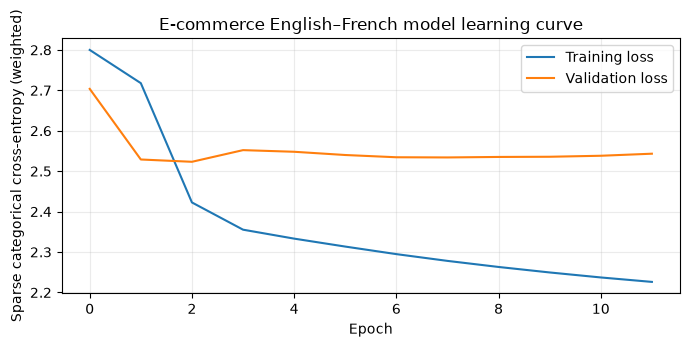

In [13]:
# Task 2 — Visualize model optimization during training.
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 3.5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Sparse categorical cross-entropy (weighted)")
plt.title("E-commerce English–French model learning curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Task 2: Findings and limitations

- **Data source:** https://www.kaggle.com/api/v1/datasets/download/devicharith/language-translation-englishfrench. This file is extracted from the real bilingual corpus.
- **Training subset:** Up to 1,200 distinct pairs out of the first 3,000 corpus records are used for an affordable CPU training run (the full original corpus was not trained end-to-end).
- **Evaluation:** 80% train and 20% held-out test. The accuracy excludes padding tokens, and exact sentence match is also reported. Token accuracy is not a substitute for translation quality.
- **E-commerce:** The corpus is general-domain; translating shopping-related text well would require domain-specific parallel data, stronger encoder–decoder or Transformer architecture, and human evaluation of product descriptions and customer reviews.
- **No fallback dataset:** No manually written examples were used for Task 2 in this execution.